# Explore the Push-T dataset

In this small notebook we will be exploring the `lerobot/pusht` dataset and observe some of its episodes.

## 0. Prepare notebook

In [66]:
import sys
import matplotlib.pyplot as plt
import numpy as np
import math
import torch
import statistics

from pathlib import Path

from pusht_bc.data import get_episode_indices, load_dataset

In [ ]:
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

print("repo root:", ROOT)

repo root: D:\Code\push-t


## 1. Load Dataset

In [ ]:
dataset = load_dataset("lerobot/pusht")
stats = dataset.meta.stats
episodes = dataset.meta.episodes

In [3]:
print("frames:", len(dataset), "| episodes:", dataset.num_episodes, "| fps:", dataset.fps)
print("episode indices:", get_episode_indices(dataset)[:5], "...")
print("\nfeatures:")

for k, v in dataset.features.items():
    print(f"  {k:20s} dtype={v['dtype']:8s} shape={tuple(v['shape'])}")
    
sample = dataset[0]
print("\none sample:")
for k, v in sample.items():
    if isinstance(v, torch.Tensor):
        print(f"  {k:20s} {str(v.dtype):15s} {tuple(v.shape)}")
    else:
        print(f"  {k:20s} {type(v).__name__}: {v!r}")

frames: 25650 | episodes: 206 | fps: 10
episode indices: [0, 1, 2, 3, 4] ...

features:
  observation.image    dtype=video    shape=(96, 96, 3)
  observation.state    dtype=float32  shape=(2,)
  action               dtype=float32  shape=(2,)
  episode_index        dtype=int64    shape=(1,)
  frame_index          dtype=int64    shape=(1,)
  timestamp            dtype=float32  shape=(1,)
  next.reward          dtype=float32  shape=(1,)
  next.done            dtype=bool     shape=(1,)
  next.success         dtype=bool     shape=(1,)
  index                dtype=int64    shape=(1,)
  task_index           dtype=int64    shape=(1,)

one sample:
  observation.state    torch.float32   (2,)
  action               torch.float32   (2,)
  episode_index        torch.int64     ()
  frame_index          torch.int64     ()
  timestamp            torch.float32   ()
  next.reward          torch.float32   ()
  next.done            torch.bool      ()
  next.success         torch.bool      ()
  index      

In [48]:
def show_frame(idx: int, ax=None):
    """
    Display one dataset frame with its state and action.

    Args:
        idx: dataset (frame) index.
        ax: matplotlib axis (None = new figure).
    Returns:
        The axis.
    """
    item = dataset[idx]

    if ax is None:
        _, ax = plt.subplots(figsize=(3, 3))

    ax.imshow(item["observation.image"].permute(1, 2, 0).numpy())
    s, a = item["observation.state"].tolist(), item["action"].tolist()
    ax.set_title(f"ep {int(item['episode_index'])} frame {int(item['frame_index'])}\n"
                 f"state ({s[0]:.0f}, {s[1]:.0f}) action ({a[0]:.0f}, {a[1]:.0f})", fontsize=8)
    ax.axis("off")

    return ax

## 2. Dataset Analysis

### 2.1 Episode lengths

In [ ]:
print(f"Max. length: {max(episodes["length"])} frames")
print(f"Min. length: {min(episodes["length"])} frames")
print(f"Mean length: {round(statistics.mean(episodes["length"]))} frames")

| Metric | Length |
| --- | --- |
| **Max. length** | 246 frames |
| **Min. length** | 49 frames |
| **Mean length** | 125 frames |

### 2.2 One episode: state vs action path

In [72]:
episode_0 = episodes[0]
for k in range(episode_0["dataset_to_index"]):
    distances = []
    for t in [0, 1, 2, 3, 4, 5]:
        state_t = dataset[t + k]["observation.state"]
        action_t = dataset[t]["action"] # Where is being told to go
        distance = math.sqrt((action_t[0] - state_t[0])**2 + (action_t[1] - state_t[0])**2)

        distances.append(distance)

    print(k, statistics.mean(distances))

0 142.76264018524913
1 145.36617142452766
2 149.04858400460284
3 154.2466480397138
4 161.31646373229202
5 170.3855728325858
6 180.95175617997222
7 191.95593953792599
8 202.64378171061048
9 212.7953162879771
10 222.33190175287208
11 231.2565599224633
12 239.71815570334775
13 248.166282606842
14 256.77350625333315
15 265.3889089609308
16 273.7665369931725
17 281.7221119010771
18 289.0849364649004
19 295.6629129611471
20 301.37561122579604
21 306.2102630062681
22 310.357830748912
23 313.7694432189754
24 316.28963154251335
25 317.7479879751065
26 317.8860298057998
27 316.42648631637576
28 312.9873055275627
29 307.2659104232337
30 298.9200926759801
31 288.07453547407687
32 275.2715832507749
33 261.18265776920566
34 246.6129090266555
35 232.3653242546157
36 219.2503081014939
37 207.79761364290323
38 198.13455758059288
39 190.1745194837374
40 183.7805909783822
41 178.796711782922
42 175.1634138523428
43 172.74217736441494
44 171.40106498726215
45 171.0671245488961
46 171.43649519344586
47 172

### 2.3 First, Middle and Last Frames

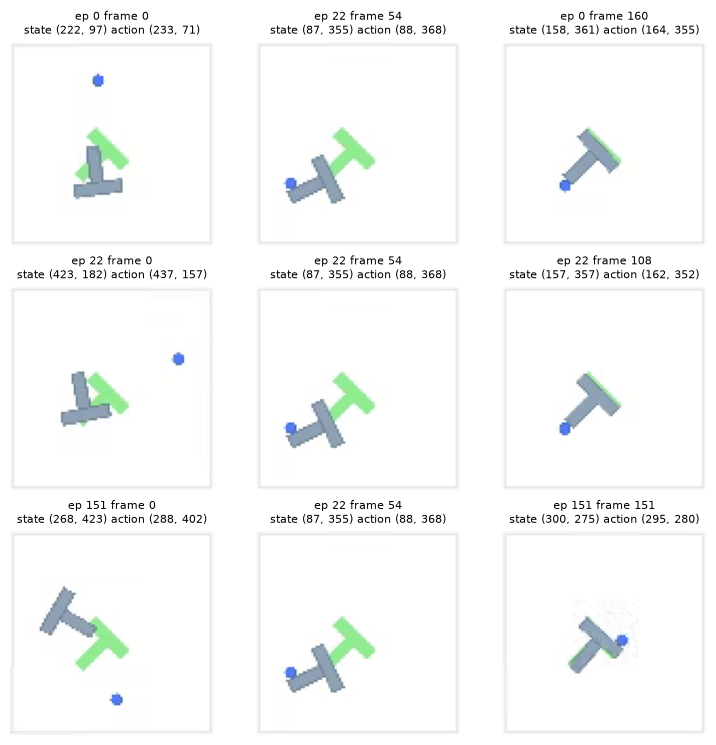

In [45]:
EPISODES = [0, 22, 151]

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for i, episode in enumerate(EPISODES):
    first_frame = episodes[episode]["dataset_from_index"]
    middle_frame = episodes[22]["dataset_from_index"] + (episodes[22]["dataset_to_index"] - episodes[22]["dataset_from_index"]) // 2
    last_frame = episodes[episode]["dataset_to_index"] - 1

    show_frame(first_frame, ax=axes[i, 0])
    show_frame(middle_frame, ax=axes[i, 1])
    show_frame(last_frame, ax=axes[i, 2])

They differ in where the circle and the 'T' start, whereas the similarity is that the target 'T' always remains in the same location.

### 2.4 Similar starts: same strategy?

My findings show that while episodes 0 and 22 begin in similar (though not identical) positions, they apply force from different regions.